# Response-State Semantic/Label/Position Remapping

This audit separates three attributes that were confounded in the prior cross-query experiment: the donor's physical side, output label, and option position.

[实验设置与运行说明](../../../docs/experiment_notes/05_appendix_content_and_encoding/9c640683e52d7478.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the response-state remapping protocol
cell_stage('Freezing support, mappings, model sites, split, and decision gates')
import hashlib
import json
from datetime import datetime, timezone

# Run qwen9b first, then qwen27b with no other changes.
MODEL_KEY = 'qwen9b'
MODEL_SPECS = {
    'qwen9b': {
        'model_id': 'Qwen/Qwen3.5-9B',
        'model_slug': 'Qwen__Qwen3.5-9B',
        'expected_layers': 32,
        'revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
        'candidate_layers': (8, 12, 16, 20, 24, 27, 31),
        'fixed_layer': None,
        'confirmatory_model': False,
    },
    'qwen27b': {
        'model_id': 'Qwen/Qwen3.5-27B',
        'model_slug': 'Qwen__Qwen3.5-27B__373612cb',
        'expected_layers': 64,
        'revision': '373612cb4f9288fcf550b526d86d85febedd9801',
        'candidate_layers': (63,),
        'fixed_layer': 63,
        'confirmatory_model': True,
    },
}
PRIMARY_MODEL_KEYS = ('qwen9b', 'qwen27b')
assert MODEL_KEY in MODEL_SPECS
SPEC = MODEL_SPECS[MODEL_KEY]
MODEL_ID = SPEC['model_id']
MODEL_SLUG = SPEC['model_slug']
MODEL_REVISION = SPEC['revision']
EXPECTED_LAYER_COUNT = SPEC['expected_layers']
CANDIDATE_LAYERS = tuple(SPEC['candidate_layers'])
CAPTURE_LAYERS = CANDIDATE_LAYERS
SITE_SCOPE = 'final_prompt_token'
SITE_LABEL = 'response_readout'

MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
SEED = 20260831
DONOR_TASKS = ('weight_more', 'weight_less')
TARGET_TASKS = ('outcome', 'weight_more', 'weight_less')
DIAGNOSTIC_VARIANTS = ('forward', 'reverse')
LABELS = ('A', 'B', 'C')
DISCOVERY_FAMILIES = 16
CONFIRMATION_FAMILIES = 32
EXPECTED_FAMILIES = DISCOVERY_FAMILIES + CONFIRMATION_FAMILIES
DISCOVERY_INTERVENTIONS_PER_FAMILY = (
    len(DONOR_TASKS) * len(CANDIDATE_LAYERS) * 2
    if SPEC['fixed_layer'] is None else 0
)
CONFIRMATION_RECORDS_PER_FAMILY = (
    len(DONOR_TASKS) * 2
    + len(DONOR_TASKS) * len(TARGET_TASKS)
    * len(DIAGNOSTIC_VARIANTS) * 3
)
EXPECTED_CONFIRMATION_RECORDS = (
    CONFIRMATION_FAMILIES * CONFIRMATION_RECORDS_PER_FAMILY
)
CAPTURE_BATCH_SIZE = 1
PATCH_CONDITION_BATCH_SIZE = 1 if MODEL_KEY == 'qwen27b' else 2
BOOTSTRAP_REPLICATES = 10000
ALPHA = 0.05
MIN_CONFIRMATION_FAMILIES = 24
CARRIER_SESOI = 0.10
CLASS_EFFECT_SESOI = 0.10
DOMINANCE_SESOI = 0.10
TARGET_CELL_SESOI = 0.05
CONFIDENCE_SESOI = 0.02
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.15
NORM_RELATIVE_TOLERANCE = 0.02
IMAGE_TOKEN_ID_OVERRIDE = None

PRIOR_ROOT = PROJECT_ROOT / 'results' / 'inverse_query_weight_route_specificity_v1'
PRIOR_MANIFEST_PATH = PRIOR_ROOT / 'inverse_query_manifest.jsonl'
PRIOR_SCENE_DIR = PRIOR_ROOT / 'rendered_scenes'
SHARED_ROOT = PROJECT_ROOT / 'results' / 'response_state_remapping_v1'
MANIFEST_PATH = SHARED_ROOT / 'remapping_manifest.jsonl'
MANIFEST_LOCK_PATH = SHARED_ROOT / 'manifest_lock.json'
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
OUTPUT_ROOT = SHARED_ROOT / 'models' / MODEL_SLUG
DISCOVERY_DIR = OUTPUT_ROOT / 'discovery'
SHARD_DIR = OUTPUT_ROOT / 'confirmation_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
CROSS_MODEL_DIR = SHARED_ROOT / 'cross_model_analysis'
for path in (
    SHARED_ROOT, OUTPUT_ROOT, DISCOVERY_DIR, SHARD_DIR,
    ANALYSIS_DIR, FIGURE_DIR, CROSS_MODEL_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n', encoding='utf-8'
    )
    temporary.replace(path)

protocol_identity = {
    'schema_version': 'response-state-remapping-protocol-1.0',
    'analysis_status': 'prospective_followup_on_locked_support',
    'models': {
        key: {
            'model_id': value['model_id'], 'revision': value['revision'],
            'candidate_layers': list(value['candidate_layers']),
            'fixed_layer': value['fixed_layer'],
            'confirmatory_model': value['confirmatory_model'],
        } for key, value in MODEL_SPECS.items()
    },
    'scope': SITE_SCOPE,
    'donor_tasks': list(DONOR_TASKS),
    'target_tasks': list(TARGET_TASKS),
    'diagnostic_variants': list(DIAGNOSTIC_VARIANTS),
    'split': {
        'discovery_families': DISCOVERY_FAMILIES,
        'confirmation_families': CONFIRMATION_FAMILIES,
        'shared_across_models': True,
    },
    'diagnostic_constraint': (
        'donor semantic, donor label, and donor position map to three '
        'different target candidates'
    ),
    'qwen9_selection': (
        'select final-token layer by identity carrier effect on discovery only'
    ),
    'qwen27_selection': 'L63 fixed before this audit',
    'primary_classes': (
        'semantic_side', 'output_label', 'option_position',
        'generic_confidence', 'mixed_or_no_stable_state'
    ),
    'class_gate': (
        'identity carrier lower CI > 0.10; class effect and dominance lower '
        'CI > 0.10; every target lower CI > 0.05; aggregate carrier, effect, '
        'and dominance BH q < 0.05'
    ),
    'random_control': 'deterministic equal-norm random direction',
    'bootstrap_unit': 'confirmation physical family',
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'seed': SEED,
    'interpretation_limit': (
        'The experiment classifies a final-token response carrier; it does '
        'not establish where the physical computation occurred upstream.'
    ),
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_KEY, MODEL_ID, '@', MODEL_REVISION)
print('Candidate/fixed layers:', CANDIDATE_LAYERS, SPEC['fixed_layer'])
print('Discovery / confirmation families:',
      DISCOVERY_FAMILIES, CONFIRMATION_FAMILIES)
print('Expected confirmation records:', EXPECTED_CONFIRMATION_RECORDS)
print('Shared output:', SHARED_ROOT)


Lock the response-state remapping protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: qwen9b Qwen/Qwen3.5-9B @ c202236235762e1c871ad0ccb60c8ee5ba337b9a
Candidate/fixed layers: (8, 12, 16, 20, 24, 27, 31) None
Discovery / confirmation families: 16 32
Expected confirmation records: 1280
Shared output: /content/drive/MyDrive/VisualTorque/results/response_state_remapping_v1


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## 2. Locked support and discovery/confirmation split


In [7]:
%%cell_progress 6/17 Lock the prior support and discovery/confirmation split
cell_stage('Reusing the exact inverse-query support and freezing the split')
from collections import Counter, defaultdict
import shutil

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_jsonl_atomic(path, rows):
    temporary = Path(path).with_suffix(Path(path).suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(path)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

def outcome(value):
    return 'left' if value > 0 else 'right' if value < 0 else 'balanced'

assert PRIOR_MANIFEST_PATH.is_file(), (
    'Run the inverse-query notebook first: ' + str(PRIOR_MANIFEST_PATH)
)
prior_manifest_sha256 = sha256_file(PRIOR_MANIFEST_PATH)
prior_rows = read_jsonl(PRIOR_MANIFEST_PATH)
assert len(prior_rows) == EXPECTED_FAMILIES
ordered = sorted(prior_rows, key=lambda row: stable_key(row['family_id']))
discovery_ids = {row['family_id'] for row in ordered[:DISCOVERY_FAMILIES]}
locked_rows = [
    {**row, 'remapping_split': (
        'discovery' if row['family_id'] in discovery_ids else 'confirmation'
    )}
    for row in prior_rows
]
assert Counter(row['remapping_split'] for row in locked_rows) == {
    'discovery': DISCOVERY_FAMILIES,
    'confirmation': CONFIRMATION_FAMILIES,
}

physics_violations = []
image_filenames = []
for row in locked_rows:
    base = row['roles']['base']
    source = row['roles']['aligned_source']
    positions = lambda role: tuple(
        (stack['side'], int(stack['distance'])) for stack in role['stacks']
    )
    units = lambda role: tuple(int(stack['units']) for stack in role['stacks'])
    if positions(base) != positions(source):
        physics_violations.append((row['family_id'], 'positions'))
    if units(base) == units(source):
        physics_violations.append((row['family_id'], 'units'))
    if int(base['features']['net_torque']) != int(source['features']['net_torque']):
        physics_violations.append((row['family_id'], 'net_torque'))
    if str(base['features']['outcome']) != str(source['features']['outcome']):
        physics_violations.append((row['family_id'], 'outcome'))
    image_filenames.extend(role['image_filename'] for role in row['roles'].values())
assert not physics_violations, physics_violations[:5]
assert all((PRIOR_SCENE_DIR / name).is_file() for name in image_filenames)

manifest_identity = {
    'schema_version': 'response-state-remapping-manifest-1.0',
    'prior_manifest_sha256': prior_manifest_sha256,
    'split_seed': SEED,
    'discovery_ids': sorted(discovery_ids),
    'confirmation_ids': sorted(
        row['family_id'] for row in locked_rows
        if row['remapping_split'] == 'confirmation'
    ),
}
if MANIFEST_PATH.is_file() and MANIFEST_LOCK_PATH.is_file():
    previous = json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == manifest_identity
    assert read_jsonl(MANIFEST_PATH) == locked_rows
else:
    write_jsonl_atomic(MANIFEST_PATH, locked_rows)
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

remapping_manifest = read_jsonl(MANIFEST_PATH)
discovery_manifest = [
    row for row in remapping_manifest if row['remapping_split'] == 'discovery'
]
confirmation_manifest = [
    row for row in remapping_manifest if row['remapping_split'] == 'confirmation'
]
RUNTIME_SCENE_DIR = Path('/content/visualtorque_response_remapping_scenes_v1')
RUNTIME_SCENE_DIR.mkdir(parents=True, exist_ok=True)
for filename in tqdm(image_filenames, desc='Caching locked images', unit='image'):
    source = PRIOR_SCENE_DIR / filename
    destination = RUNTIME_SCENE_DIR / filename
    if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
        shutil.copy2(source, destination)
assert all((RUNTIME_SCENE_DIR / name).is_file() for name in image_filenames)
print('Prior manifest:', prior_manifest_sha256)
print('Discovery / confirmation:',
      len(discovery_manifest), len(confirmation_manifest))


Lock the prior support and discovery/confirmation split:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Caching locked images:   0%|          | 0/96 [00:00<?, ?image/s]

Prior manifest: sha256:514419513bfe9ec3cb2aa7e3e416097917944a41eb2915797b0089d2aae2a4a9
Discovery / confirmation: 16 32


In [8]:
%%cell_progress 7/17 Load the pinned model and mapped decoder layers
cell_stage(f'Loading {MODEL_KEY} weights for response-state remapping')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers',
        'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
assert all(0 <= layer < len(DECODER_LAYERS) for layer in CAPTURE_LAYERS)
print('Layer path:', LAYER_PATH)
print('Capture layers:', CAPTURE_LAYERS)


Load the pinned model and mapped decoder layers:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-9B',
 'requested_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'resolved_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 9409813744,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Capture layers: (8, 12, 16, 20, 24, 27, 31)


## 3. Three-way response-state remapping


In [9]:
%%cell_progress 8/17 Define reference and three-way diagnostic mappings
cell_stage('Constructing mappings that separate semantic, label, and position')
import math
from visual_torque_toolkit.behavior import PromptCondition
from visual_torque_toolkit.behavior.data import BehaviorExample

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    'intervals from the center pivot. Torque equals weight times distance. '
    'Total torque on a side is the sum over stacks on that side.'
)
QUESTION_TEXT = {
    'outcome': 'Which way will the balance scale tip?',
    'weight_more': 'Which side has more total weight?',
    'weight_less': 'Which side has less total weight?',
}
SEMANTIC_TEXT = {
    'left': 'left side', 'balanced': 'equal', 'right': 'right side',
}

def task_semantic(features, task):
    if task == 'outcome':
        value = int(features['net_torque'])
    elif task == 'weight_more':
        value = int(features['weight_score'])
    elif task == 'weight_less':
        value = -int(features['weight_score'])
    else:
        raise KeyError(task)
    return outcome(value)

def reference_mapping(row):
    semantics = ['left', 'balanced', 'right']
    offset = int(stable_key(f"options:{row['family_id']}")[:8], 16) % 3
    semantics = semantics[offset:] + semantics[:offset]
    return tuple({
        'position': index, 'label': LABELS[index], 'semantic': semantics[index]
    } for index in range(3))

def diagnostic_mapping(row, donor_semantic, variant):
    reference = reference_mapping(row)
    donor_position = next(
        item['position'] for item in reference
        if item['semantic'] == donor_semantic
    )
    donor_label = reference[donor_position]['label']
    other_positions = [value for value in range(3) if value != donor_position]
    other_semantics = [
        value for value in ('left', 'balanced', 'right')
        if value != donor_semantic
    ]
    other_labels = [value for value in LABELS if value != donor_label]
    if variant == 'reverse':
        other_semantics.reverse()
        other_labels.reverse()
    elif variant != 'forward':
        raise KeyError(variant)
    label_position, semantic_position = other_positions
    mapping = [None, None, None]
    mapping[donor_position] = {
        'position': donor_position,
        'label': other_labels[0],
        'semantic': other_semantics[0],
    }
    mapping[label_position] = {
        'position': label_position,
        'label': donor_label,
        'semantic': other_semantics[1],
    }
    mapping[semantic_position] = {
        'position': semantic_position,
        'label': other_labels[1],
        'semantic': donor_semantic,
    }
    assert {item['label'] for item in mapping} == set(LABELS)
    assert {item['semantic'] for item in mapping} == {'left', 'balanced', 'right'}
    semantic_candidate = next(
        item['label'] for item in mapping if item['semantic'] == donor_semantic
    )
    label_candidate = donor_label
    position_candidate = mapping[donor_position]['label']
    assert len({semantic_candidate, label_candidate, position_candidate}) == 3
    diagnostics = {
        'donor_semantic': donor_semantic,
        'donor_label': donor_label,
        'donor_position': donor_position,
        'semantic_candidate': semantic_candidate,
        'label_candidate': label_candidate,
        'position_candidate': position_candidate,
    }
    return tuple(mapping), diagnostics

def semantics_by_label(mapping):
    return tuple(
        next(item['semantic'] for item in mapping if item['label'] == label)
        for label in LABELS
    )

def custom_prompt(task, mapping):
    options = '\n'.join(
        f"{item['label']}. {SEMANTIC_TEXT[item['semantic']]}"
        for item in mapping
    )
    return '\n\n'.join([
        'Answer this question using only the supplied balance-scale scene.',
        RULE_TEXT,
        'Question: ' + QUESTION_TEXT[task],
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_example(row, task, role, mapping, name):
    role_record = row['roles'][role]
    features = role_record['features']
    semantics = semantics_by_label(mapping)
    gold = task_semantic(features, task)
    return BehaviorExample(
        example_id=f"remap:{row['family_id']}:{name}:{role}",
        question_id=f"remap_{row['family_id']}_{name}",
        scene_id=str(role_record['scene_id']),
        condition=PromptCondition.IMAGE_RULE,
        question_kind=task,
        variant='response_state_remapping',
        split=str(row['remapping_split']),
        problem_type='semantic_label_position_separation',
        outcome=gold,
        net_torque=int(features['net_torque']),
        prompt=custom_prompt(task, mapping),
        image_path=(RUNTIME_SCENE_DIR / role_record['image_filename']).resolve(),
        labels=LABELS,
        option_text=tuple(
            SEMANTIC_TEXT[value] for value in semantics
        ),
        option_semantics=semantics,
        gold_label=LABELS[semantics.index(gold)],
        gold_semantic=gold,
    )

def donor_semantic_for(row, donor_task):
    return task_semantic(row['roles']['aligned_source']['features'], donor_task)

def build_reference_examples(row):
    mapping = reference_mapping(row)
    examples = {}
    for donor_task in DONOR_TASKS:
        for role in ('base', 'aligned_source'):
            key = f'ref__{donor_task}__{role}'
            examples[key] = make_example(
                row, donor_task, role, mapping, f'ref_{donor_task}'
            )
    return examples

def build_diagnostic_examples(row):
    examples = {}
    diagnostics = {}
    for donor_task in DONOR_TASKS:
        donor_semantic = donor_semantic_for(row, donor_task)
        for target_task in TARGET_TASKS:
            for variant in DIAGNOSTIC_VARIANTS:
                mapping, info = diagnostic_mapping(
                    row, donor_semantic, variant
                )
                key = f'diag__{donor_task}__{target_task}__{variant}'
                examples[key] = make_example(
                    row, target_task, 'base', mapping, key
                )
                diagnostics[key] = info
    return examples, diagnostics

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(output.last_hidden_state):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )), fixed_prefix,
    )
    return {'examples': examples, 'inputs': inputs, 'token_by_label': token_by_label}

def final_mask(prepared):
    assert len(prepared['examples']) == 1
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    mask = torch.zeros_like(attention)
    mask[int(torch.where(attention)[0][-1])] = True
    return mask

print('Reference and three-way diagnostic mappings ready.')


Define reference and three-way diagnostic mappings:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Reference and three-way diagnostic mappings ready.


In [10]:
%%cell_progress 9/17 Define final-token capture and intervention scorers
cell_stage('Defining variable-layer final-token transport')

def score_records(prepared, logits):
    logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for index, example in enumerate(prepared['examples']):
        scores = [
            float(logprobs[index, prepared['token_by_label'][label]].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        probabilities = [value / sum(weights) for value in weights]
        predicted = int(np.argmax(scores))
        records.append({
            'candidate_labels': list(example.labels),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': probabilities,
            'predicted_label': example.labels[predicted],
            'predicted_semantic': example.option_semantics[predicted],
            'gold_label': example.gold_label,
            'gold_semantic': example.gold_semantic,
        })
    return records

def forward_capture(prepared, layers):
    hidden_by_layer = {}
    handles = []
    for layer in layers:
        def hook(_module, _inputs, output, layer=layer):
            hidden_by_layer[layer] = output_hidden_tensor(
                output
            ).detach().cpu().clone()
        handles.append(DECODER_LAYERS[layer].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits), hidden_by_layer

def capture_examples(examples, layers):
    scores = {}
    hidden = {name: {} for name in examples}
    masks = {}
    for name, example in examples.items():
        prepared = prepare_examples([example])
        masks[name] = final_mask(prepared)
        current_scores, current_hidden = forward_capture(prepared, layers)
        scores[name] = current_scores[0]
        for layer, tensor in current_hidden.items():
            hidden[name][layer] = tensor[0]
        del prepared, current_hidden
    return scores, hidden, masks

def selected_norm(tensor):
    return float(torch.linalg.vector_norm(tensor.float()))

def matched_random(tensor, key):
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(stable_key(key)[:16], 16) % (2**63 - 1))
    noise = torch.randn(tensor.shape, generator=generator, dtype=torch.float32)
    return (noise * (selected_norm(tensor) / selected_norm(noise))).to(tensor.dtype)

def forward_intervention_chunk(prepared, conditions):
    assert len(prepared['examples']) == len(conditions)
    layers = {int(row['layer_index']) for row in conditions}
    assert len(layers) == 1
    layer = next(iter(layers))
    payloads = torch.stack([row['payload_selected'] for row in conditions])
    masks = torch.stack([row['target_mask'] for row in conditions])
    modes = [row['intervention_mode'] for row in conditions]
    counts = []
    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        payload = payloads.to(device=hidden.device, dtype=hidden.dtype)
        mask = masks.to(device=hidden.device)
        modified = hidden.clone()
        counts.clear()
        for index, mode in enumerate(modes):
            current = mask[index]
            assert int(current.sum()) == int(payload[index].shape[0]) == 1
            if mode == 'add':
                modified[index, current] = hidden[index, current] + payload[index]
            elif mode == 'replace':
                modified[index, current] = payload[index]
            else:
                raise ValueError(mode)
            counts.append(int(current.sum()))
        return replace_output_hidden(output, modified)
    handle = DECODER_LAYERS[layer].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    records = score_records(prepared, output.logits)
    for record, condition, count in zip(records, conditions, counts):
        record.update({
            key: value for key, value in condition.items()
            if key not in ('payload_selected', 'target_mask')
        })
        record['patched_tokens'] = count
    return records

def score_conditions(example, conditions):
    records = []
    grouped = defaultdict(list)
    for condition in conditions:
        grouped[int(condition['layer_index'])].append(condition)
    for layer_conditions in grouped.values():
        for start in range(0, len(layer_conditions), PATCH_CONDITION_BATCH_SIZE):
            actual = layer_conditions[start:start + PATCH_CONDITION_BATCH_SIZE]
            padded = list(actual)
            while len(padded) < PATCH_CONDITION_BATCH_SIZE:
                padded.append(padded[-1])
            prepared = prepare_examples([example] * len(padded))
            records.extend(forward_intervention_chunk(
                prepared, padded
            )[:len(actual)])
            del prepared
    return records

def centered_scores(record):
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return values - values.mean()

def label_score(record, label):
    labels = list(record['candidate_labels'])
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    index = labels.index(label)
    other = np.delete(values, index)
    return float(values[index] - np.logaddexp.reduce(other))

def entropy(record):
    probabilities = np.asarray(record['candidate_probabilities'], dtype=float)
    return float(-np.sum(probabilities * np.log(np.clip(probabilities, 1e-12, 1))))

print('Final-token scorers ready.')


Define final-token capture and intervention scorers:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Final-token scorers ready.


In [11]:
%%cell_progress 10/17 Run mapping, token, and parity smoke tests
cell_stage('Checking three-way separation and exact self replay')
smoke_row = confirmation_manifest[0]
reference_examples = build_reference_examples(smoke_row)
diagnostic_examples, diagnostic_info = build_diagnostic_examples(smoke_row)
for key, info in diagnostic_info.items():
    assert len({
        info['semantic_candidate'], info['label_candidate'],
        info['position_candidate'],
    }) == 3, key

smoke_examples = {
    **reference_examples,
    **{key: value for key, value in diagnostic_examples.items()
       if key.startswith('diag__weight_more__outcome')},
}
smoke_scores, smoke_hidden, smoke_masks = capture_examples(
    smoke_examples, CANDIDATE_LAYERS
)
token_ids = []
for name, example in smoke_examples.items():
    prepared = prepare_examples([example])
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    token_ids.append(ids[final_mask(prepared)].tolist())
assert all(value == token_ids[0] for value in token_ids)

smoke_layer = SPEC['fixed_layer'] or CANDIDATE_LAYERS[-1]
target_key = 'diag__weight_more__outcome__forward'
self_condition = {
    'family_id': smoke_row['family_id'], 'condition': 'self_replay',
    'layer_index': smoke_layer, 'intervention_mode': 'replace',
    'payload_selected': smoke_hidden[target_key][smoke_layer][smoke_masks[target_key]],
    'target_mask': smoke_masks[target_key],
}
self_record = score_conditions(
    smoke_examples[target_key], [self_condition]
)[0]
self_error = float(np.max(np.abs(
    centered_scores(self_record) - centered_scores(smoke_scores[target_key])
)))
assert self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, self_error
assert self_record['patched_tokens'] == 1
print('Three diagnostic candidates:', diagnostic_info[target_key])
print('Final token ID:', token_ids[0])
print('Centered self parity:', self_error)
del smoke_hidden
torch.cuda.empty_cache()


Run mapping, token, and parity smoke tests:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Three diagnostic candidates: {'donor_semantic': 'left', 'donor_label': 'C', 'donor_position': 2, 'semantic_candidate': 'B', 'label_candidate': 'C', 'position_candidate': 'A'}
Final token ID: [271]
Centered self parity: 0.0


In [12]:
%%cell_progress 11/17 Select or verify the final-token carrier layer
cell_stage('Using discovery families only for Qwen-9B layer selection')

selection_path = DISCOVERY_DIR / 'selected_layer.json'
discovery_records_path = DISCOVERY_DIR / 'layer_records.jsonl'

def semantic_score(record, semantic):
    semantics = list(record['candidate_semantics'])
    label = record['candidate_labels'][semantics.index(semantic)]
    return label_score(record, label)

if SPEC['fixed_layer'] is not None:
    SELECTED_LAYER = int(SPEC['fixed_layer'])
    selection_payload = {
        'schema_version': 'response-carrier-selection-1.0',
        'model_key': MODEL_KEY, 'selection_mode': 'prior_fixed',
        'selected_layer': SELECTED_LAYER,
        'discovery_family_ids': [],
    }
    if selection_path.is_file():
        assert json.loads(selection_path.read_text(encoding='utf-8')) == selection_payload
    else:
        write_json_atomic(selection_path, selection_payload)
else:
    if selection_path.is_file() and discovery_records_path.is_file():
        selection_payload = json.loads(selection_path.read_text(encoding='utf-8'))
        SELECTED_LAYER = int(selection_payload['selected_layer'])
    else:
        discovery_records = []
        for row in tqdm(discovery_manifest, desc='Discovering final-token carrier', unit='family'):
            examples = build_reference_examples(row)
            scores, hidden, masks = capture_examples(examples, CANDIDATE_LAYERS)
            for donor_task in DONOR_TASKS:
                base_key = f'ref__{donor_task}__base'
                source_key = f'ref__{donor_task}__aligned_source'
                base_semantic = task_semantic(row['roles']['base']['features'], donor_task)
                source_semantic = task_semantic(
                    row['roles']['aligned_source']['features'], donor_task
                )
                assert base_semantic != source_semantic
                base_margin = (
                    semantic_score(scores[base_key], source_semantic)
                    - semantic_score(scores[base_key], base_semantic)
                )
                for layer in CANDIDATE_LAYERS:
                    delta = (
                        hidden[source_key][layer][masks[source_key]]
                        - hidden[base_key][layer][masks[base_key]]
                    )
                    random = matched_random(
                        delta, f"discovery:{row['family_id']}:{donor_task}:{layer}"
                    )
                    conditions = []
                    for intervention, payload in (
                        ('donor_delta', delta), ('random', random),
                    ):
                        conditions.append({
                            'family_id': row['family_id'],
                            'donor_task': donor_task,
                            'condition': intervention,
                            'layer_index': layer,
                            'intervention_mode': 'add',
                            'payload_selected': payload,
                            'target_mask': masks[base_key],
                        })
                    current = score_conditions(examples[base_key], conditions)
                    shifts = {}
                    for record in current:
                        margin = (
                            semantic_score(record, source_semantic)
                            - semantic_score(record, base_semantic)
                        )
                        shifts[record['condition']] = margin - base_margin
                    discovery_records.append({
                        'family_id': row['family_id'],
                        'donor_task': donor_task, 'layer_index': layer,
                        'specific_source_transfer': float(
                            shifts['donor_delta'] - shifts['random']
                        ),
                    })
            del hidden
            torch.cuda.empty_cache()
        discovery_frame = pd.DataFrame(discovery_records)
        layer_summary = discovery_frame.groupby('layer_index')[
            'specific_source_transfer'
        ].agg(['count', 'mean']).reset_index()
        SELECTED_LAYER = int(layer_summary.sort_values(
            ['mean', 'layer_index'], ascending=[False, True]
        ).iloc[0]['layer_index'])
        write_jsonl_atomic(discovery_records_path, discovery_records)
        selection_payload = {
            'schema_version': 'response-carrier-selection-1.0',
            'model_key': MODEL_KEY, 'selection_mode': 'discovery_argmax',
            'candidate_layers': list(CANDIDATE_LAYERS),
            'selected_layer': SELECTED_LAYER,
            'discovery_family_ids': sorted(
                row['family_id'] for row in discovery_manifest
            ),
            'layer_summary': json.loads(layer_summary.to_json(orient='records')),
        }
        write_json_atomic(selection_path, selection_payload)
        display(layer_summary)
assert SELECTED_LAYER in CANDIDATE_LAYERS
print('Selected confirmation layer:', SELECTED_LAYER)


Select or verify the final-token carrier layer:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

Discovering final-token carrier:   0%|          | 0/16 [00:00<?, ?family/s]

,layer_index,count,mean
0,8,32,0.000528
1,12,32,0.005954
2,16,32,0.002494
3,20,32,0.061857
4,24,32,0.203008
5,27,32,0.169625
6,31,32,1.167008


Selected confirmation layer: 31


## 4. Held-out confirmation and abstraction decision


In [13]:
%%cell_progress 12/17 Capture or resume remapping confirmation shards
cell_stage('Transporting reference donor states into three-way diagnostic prompts')

capture_identity = {
    'schema_version': 'response-state-remapping-capture-1.1',
    'protocol_identity': protocol_identity,
    'prior_manifest_sha256': prior_manifest_sha256,
    'confirmation_family_ids': sorted(
        row['family_id'] for row in confirmation_manifest
    ),
    'model_id': MODEL_ID,
    'resolved_revision': adapter.metadata['resolved_revision'],
    'selected_layer': SELECTED_LAYER,
    'scope': SITE_SCOPE,
    'records_per_family': CONFIRMATION_RECORDS_PER_FAMILY,
}
CAPTURE_SHA256 = 'sha256:' + hashlib.sha256(
    json.dumps(capture_identity, sort_keys=True).encode('utf-8')
).hexdigest()
config_path = OUTPUT_ROOT / 'capture_config.json'
if config_path.is_file():
    previous = json.loads(config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity
else:
    write_json_atomic(config_path, {
        'identity': capture_identity,
        'capture_identity_sha256': CAPTURE_SHA256,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
    })

completed_ids = set()
for path in sorted(SHARD_DIR.glob('*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    assert len(payload['patch_records']) == CONFIRMATION_RECORDS_PER_FAMILY
    completed_ids.add(payload['family_id'])
print('Completed / confirmation:', len(completed_ids), len(confirmation_manifest))

for row in tqdm(confirmation_manifest, desc=f'{MODEL_KEY} remapping', unit='family'):
    family_id = str(row['family_id'])
    if family_id in completed_ids:
        continue
    reference_examples = build_reference_examples(row)
    diagnostic_examples, diagnostic_info = build_diagnostic_examples(row)
    all_examples = {**reference_examples, **diagnostic_examples}
    scores, hidden, masks = capture_examples(all_examples, (SELECTED_LAYER,))
    donor_deltas = {}
    random_deltas = {}
    donor_norms = {}
    for donor_task in DONOR_TASKS:
        base_key = f'ref__{donor_task}__base'
        source_key = f'ref__{donor_task}__aligned_source'
        delta = (
            hidden[source_key][SELECTED_LAYER][masks[source_key]]
            - hidden[base_key][SELECTED_LAYER][masks[base_key]]
        )
        donor_deltas[donor_task] = delta
        donor_norms[donor_task] = selected_norm(delta)
        random_deltas[donor_task] = matched_random(
            delta, f'confirmation:{family_id}:{donor_task}'
        )
    patch_records = []
    for donor_task in DONOR_TASKS:
        reference_key = f'ref__{donor_task}__base'
        for condition, payload in (
            ('identity_donor', donor_deltas[donor_task]),
            ('identity_random', random_deltas[donor_task]),
        ):
            patch_records.extend(score_conditions(
                reference_examples[reference_key], [{
                    'family_id': family_id, 'mapping_type': 'identity',
                    'variant': 'reference', 'donor_task': donor_task,
                    'target_task': donor_task, 'condition': condition,
                    'layer_index': SELECTED_LAYER,
                     'intervention_mode': 'add',
                     'payload_selected': payload,
                     'target_mask': masks[reference_key],
                     'donor_norm': donor_norms[donor_task],
                     'applied_norm': selected_norm(payload),
                 }]
            ))
        for target_task in TARGET_TASKS:
            for variant in DIAGNOSTIC_VARIANTS:
                key = f'diag__{donor_task}__{target_task}__{variant}'
                conditions = [{
                    'family_id': family_id, 'mapping_type': 'diagnostic',
                    'variant': variant, 'donor_task': donor_task,
                    'target_task': target_task, 'condition': 'self_replay',
                    'layer_index': SELECTED_LAYER,
                    'intervention_mode': 'replace',
                     'payload_selected': hidden[key][SELECTED_LAYER][masks[key]],
                     'target_mask': masks[key],
                     'donor_norm': None,
                     'applied_norm': selected_norm(
                         hidden[key][SELECTED_LAYER][masks[key]]
                     ),
                 }]
                for condition, payload in (
                    ('diagnostic_donor', donor_deltas[donor_task]),
                    ('diagnostic_random', random_deltas[donor_task]),
                ):
                    conditions.append({
                        'family_id': family_id,
                        'mapping_type': 'diagnostic', 'variant': variant,
                        'donor_task': donor_task, 'target_task': target_task,
                        'condition': condition, 'layer_index': SELECTED_LAYER,
                         'intervention_mode': 'add',
                         'payload_selected': payload, 'target_mask': masks[key],
                         'donor_norm': donor_norms[donor_task],
                         'applied_norm': selected_norm(payload),
                     })
                current = score_conditions(diagnostic_examples[key], conditions)
                for record in current:
                    record['diagnostics'] = diagnostic_info[key]
                    record['target_key'] = key
                patch_records.extend(current)
    assert len(patch_records) == CONFIRMATION_RECORDS_PER_FAMILY
    write_json_atomic(SHARD_DIR / f'{family_id}.json', {
        'schema_version': 'response-state-remapping-shard-1.1',
        'capture_identity_sha256': CAPTURE_SHA256,
        'family_id': family_id,
        'baseline_scores': scores,
        'diagnostic_info': diagnostic_info,
        'donor_norms': donor_norms,
        'patch_records': patch_records,
    })
    del hidden
    torch.cuda.empty_cache()

shards = sorted(SHARD_DIR.glob('*.json'))
assert len(shards) == CONFIRMATION_FAMILIES
assert sum(len(json.loads(path.read_text(encoding='utf-8'))['patch_records'])
           for path in shards) == EXPECTED_CONFIRMATION_RECORDS
print('Confirmation complete:', len(shards), 'families')


Capture or resume remapping confirmation shards:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Completed / confirmation: 0 32


qwen9b remapping:   0%|          | 0/32 [00:00<?, ?family/s]

Confirmation complete: 32 families


In [14]:
%%cell_progress 13/17 Release GPU and test competing response-state classes
cell_stage('Assembling diagnostic effects and frozen class decisions')
import gc
del adapter
gc.collect()
torch.cuda.empty_cache()

def find_record(records, donor_task, target_task, variant, condition):
    matches = [
        record for record in records
        if record['donor_task'] == donor_task
        and record['target_task'] == target_task
        and record['variant'] == variant
        and record['condition'] == condition
    ]
    assert len(matches) == 1, (donor_task, target_task, variant, condition)
    return matches[0]

def bootstrap_summary(values, key, directional=True):
    array = np.asarray(values, dtype=float)
    assert len(array) >= MIN_CONFIRMATION_FAMILIES and np.isfinite(array).all()
    generator = np.random.default_rng(int(stable_key(
        f'bootstrap:{MODEL_KEY}:{key}'
    )[:16], 16))
    draws = generator.choice(
        array, size=(BOOTSTRAP_REPLICATES, len(array)), replace=True
    ).mean(axis=1)
    ci_low, ci_high = np.quantile(draws, [ALPHA / 2, 1 - ALPHA / 2])
    if directional:
        p_value = float((1 + np.sum(draws <= 0)) / (BOOTSTRAP_REPLICATES + 1))
    else:
        p_value = float(min(1, 2 * min(
            (1 + np.sum(draws <= 0)) / (BOOTSTRAP_REPLICATES + 1),
            (1 + np.sum(draws >= 0)) / (BOOTSTRAP_REPLICATES + 1),
        )))
    return {
        'n': len(array), 'mean': float(array.mean()),
        'ci_low': float(ci_low), 'ci_high': float(ci_high),
        'p_value': p_value,
    }

def bh_adjust(values):
    values = np.asarray(values, dtype=float)
    order = np.argsort(values)
    adjusted = np.empty_like(values)
    running = 1.0
    for reverse_rank in range(len(values) - 1, -1, -1):
        index = order[reverse_rank]
        rank = reverse_rank + 1
        running = min(running, values[index] * len(values) / rank)
        adjusted[index] = running
    return adjusted

estimand_rows = []
identity_rows = []
self_rows = []
behavior_rows = []
for shard_path in tqdm(sorted(SHARD_DIR.glob('*.json')), desc='Estimands', unit='family'):
    payload = json.loads(shard_path.read_text(encoding='utf-8'))
    family_id = payload['family_id']
    records = payload['patch_records']
    for donor_task in DONOR_TASKS:
        base_key = f'ref__{donor_task}__base'
        base = payload['baseline_scores'][base_key]
        row = next(item for item in confirmation_manifest if item['family_id'] == family_id)
        base_semantic = task_semantic(row['roles']['base']['features'], donor_task)
        source_semantic = donor_semantic_for(row, donor_task)
        base_margin = semantic_score(base, source_semantic) - semantic_score(base, base_semantic)
        donor_record = find_record(records, donor_task, donor_task, 'reference', 'identity_donor')
        random_record = find_record(records, donor_task, donor_task, 'reference', 'identity_random')
        identity_rows.append({
            'family_id': family_id, 'donor_task': donor_task,
            'effect': float(
                (semantic_score(donor_record, source_semantic)
                 - semantic_score(donor_record, base_semantic) - base_margin)
                - (semantic_score(random_record, source_semantic)
                   - semantic_score(random_record, base_semantic) - base_margin)
            ),
        })
        for target_task in TARGET_TASKS:
            for variant in DIAGNOSTIC_VARIANTS:
                key = f'diag__{donor_task}__{target_task}__{variant}'
                baseline = payload['baseline_scores'][key]
                info = payload['diagnostic_info'][key]
                donor = find_record(
                    records, donor_task, target_task, variant, 'diagnostic_donor'
                )
                random = find_record(
                    records, donor_task, target_task, variant, 'diagnostic_random'
                )
                self_record = find_record(
                    records, donor_task, target_task, variant, 'self_replay'
                )
                effects = {}
                for state_class, candidate_key in (
                    ('semantic', 'semantic_candidate'),
                    ('label', 'label_candidate'),
                    ('position', 'position_candidate'),
                ):
                    label = info[candidate_key]
                    effects[state_class] = float(
                        (label_score(donor, label) - label_score(baseline, label))
                        - (label_score(random, label) - label_score(baseline, label))
                    )
                estimand_rows.append({
                    'family_id': family_id, 'donor_task': donor_task,
                    'target_task': target_task, 'variant': variant,
                    'semantic_effect': effects['semantic'],
                    'label_effect': effects['label'],
                    'position_effect': effects['position'],
                    'confidence_effect': float(
                        (entropy(baseline) - entropy(donor))
                        - (entropy(baseline) - entropy(random))
                    ),
                    'baseline_predicted_label': baseline['predicted_label'],
                    'donor_predicted_label': donor['predicted_label'],
                    **info,
                })
                self_rows.append({
                    'family_id': family_id, 'target_key': key,
                    'error': float(np.max(np.abs(
                        centered_scores(self_record) - centered_scores(baseline)
                    ))),
                })
                behavior_rows.append({
                    'family_id': family_id, 'target_task': target_task,
                    'variant': variant,
                    'correct': baseline['predicted_semantic'] == baseline['gold_semantic'],
                })

estimand_frame = pd.DataFrame(estimand_rows)
identity_frame = pd.DataFrame(identity_rows)
self_frame = pd.DataFrame(self_rows)
behavior_frame = pd.DataFrame(behavior_rows)
assert len(estimand_frame) == (
    CONFIRMATION_FAMILIES * len(DONOR_TASKS)
    * len(TARGET_TASKS) * len(DIAGNOSTIC_VARIANTS)
)

family_rows = []
for family_id, frame in estimand_frame.groupby('family_id'):
    semantic = float(frame['semantic_effect'].mean())
    label = float(frame['label_effect'].mean())
    position = float(frame['position_effect'].mean())
    family_rows.append({
        'family_id': family_id,
        'semantic_effect': semantic,
        'label_effect': label,
        'position_effect': position,
        'semantic_dominance': semantic - max(label, position),
        'label_dominance': label - max(semantic, position),
        'position_dominance': position - max(semantic, label),
        'confidence_effect': float(frame['confidence_effect'].mean()),
        'identity_carrier': float(identity_frame[
            identity_frame['family_id'] == family_id
        ]['effect'].mean()),
    })
family_frame = pd.DataFrame(family_rows)

test_rows = []
for metric in (
    'identity_carrier', 'semantic_effect', 'label_effect', 'position_effect',
    'semantic_dominance', 'label_dominance', 'position_dominance',
    'confidence_effect',
):
    test_rows.append({
        'test_family': 'aggregate', 'target_task': 'all', 'metric': metric,
        'primary_test': metric in (
            'identity_carrier',
            'semantic_effect', 'label_effect', 'position_effect',
            'semantic_dominance', 'label_dominance', 'position_dominance',
        ),
        **bootstrap_summary(family_frame[metric], f'aggregate:{metric}'),
    })
for target_task in TARGET_TASKS:
    current = estimand_frame[estimand_frame['target_task'] == target_task]
    per_family = current.groupby('family_id')[[
        'semantic_effect', 'label_effect', 'position_effect'
    ]].mean()
    for state_class in ('semantic', 'label', 'position'):
        others = [value for value in ('semantic', 'label', 'position') if value != state_class]
        dominance = per_family[f'{state_class}_effect'] - per_family[[
            f'{value}_effect' for value in others
        ]].max(axis=1)
        test_rows.append({
            'test_family': 'target_dominance', 'target_task': target_task,
            'metric': f'{state_class}_dominance', 'primary_test': False,
            **bootstrap_summary(dominance, f'target:{target_task}:{state_class}'),
        })

tests_frame = pd.DataFrame(test_rows)
primary = tests_frame.index[tests_frame['primary_test']].tolist()
tests_frame['q_value'] = np.nan
tests_frame.loc[primary, 'q_value'] = bh_adjust(
    tests_frame.loc[primary, 'p_value'].to_numpy(float)
)
def aggregate_test(metric):
    rows = tests_frame[(tests_frame['test_family'] == 'aggregate')
                       & (tests_frame['metric'] == metric)]
    assert len(rows) == 1
    return rows.iloc[0]
def target_test(target, metric):
    rows = tests_frame[(tests_frame['test_family'] == 'target_dominance')
                       & (tests_frame['target_task'] == target)
                       & (tests_frame['metric'] == metric)]
    assert len(rows) == 1
    return rows.iloc[0]

carrier = aggregate_test('identity_carrier')
class_status = {}
for state_class in ('semantic', 'label', 'position'):
    effect = aggregate_test(f'{state_class}_effect')
    dominance = aggregate_test(f'{state_class}_dominance')
    class_status[state_class] = bool(
        carrier['ci_low'] > CARRIER_SESOI
        and carrier['q_value'] < ALPHA
        and effect['ci_low'] > CLASS_EFFECT_SESOI
        and effect['q_value'] < ALPHA
        and dominance['ci_low'] > DOMINANCE_SESOI
        and dominance['q_value'] < ALPHA
        and all(target_test(
            target, f'{state_class}_dominance'
        )['ci_low'] > TARGET_CELL_SESOI for target in TARGET_TASKS)
    )
passing = [key for key, value in class_status.items() if value]
confidence = aggregate_test('confidence_effect')
if len(passing) == 1:
    primary_decision = passing[0] + '_response_state'
elif len(passing) > 1:
    primary_decision = 'mixed_response_state'
elif carrier['ci_low'] <= CARRIER_SESOI:
    primary_decision = 'no_stable_final_token_carrier'
elif confidence['ci_low'] > CONFIDENCE_SESOI:
    primary_decision = 'generic_confidence_state'
else:
    primary_decision = 'mixed_or_unresolved_response_state'

decision_frame = pd.DataFrame([{
    'model_key': MODEL_KEY, 'selected_layer': SELECTED_LAYER,
    'selection_mode': selection_payload['selection_mode'],
    'primary_decision': primary_decision,
    'semantic_passed': class_status['semantic'],
    'label_passed': class_status['label'],
    'position_passed': class_status['position'],
    'identity_carrier_effect': float(carrier['mean']),
    'semantic_effect': float(aggregate_test('semantic_effect')['mean']),
    'label_effect': float(aggregate_test('label_effect')['mean']),
    'position_effect': float(aggregate_test('position_effect')['mean']),
    'semantic_dominance': float(aggregate_test('semantic_dominance')['mean']),
    'label_dominance': float(aggregate_test('label_dominance')['mean']),
    'position_dominance': float(aggregate_test('position_dominance')['mean']),
    'confidence_effect': float(confidence['mean']),
}])
estimand_frame.to_csv(ANALYSIS_DIR / 'remapping_estimands.csv', index=False)
family_frame.to_csv(ANALYSIS_DIR / 'family_metrics.csv', index=False)
tests_frame.to_csv(ANALYSIS_DIR / 'remapping_tests.csv', index=False)
decision_frame.to_csv(ANALYSIS_DIR / 'remapping_decision.csv', index=False)
display(tests_frame.round(4))
display(decision_frame)


Release GPU and test competing response-state classes:  71%|#######   | 12/17 [00:00<?, ?cell/s]

Estimands:   0%|          | 0/32 [00:00<?, ?family/s]

,test_family,target_task,metric,primary_test,n,mean,ci_low,ci_high,p_value,q_value
0,aggregate,all,identity_carrier,True,32,1.4957,0.9332,2.0726,0.0001,0.0002
1,aggregate,all,semantic_effect,True,32,-0.3065,-0.4269,-0.1913,1.0000,1.0000
2,aggregate,all,label_effect,True,32,0.6051,0.3746,0.8452,0.0001,0.0002
3,aggregate,all,position_effect,True,32,-0.2674,-0.3730,-0.1708,1.0000,1.0000
4,aggregate,all,semantic_dominance,True,32,-0.9699,-1.3040,-0.6463,1.0000,1.0000
5,aggregate,all,label_dominance,True,32,0.8448,0.5119,1.1775,0.0001,0.0002
6,aggregate,all,position_dominance,True,32,-0.9344,-1.2647,-0.6331,1.0000,1.0000
7,aggregate,all,confidence_effect,False,32,0.0122,0.0002,0.0259,0.0226,NaN
8,target_dominance,outcome,semantic_dominance,False,32,-0.9601,-1.2899,-0.6497,1.0000,NaN
9,target_dominance,outcome,label_dominance,False,32,0.8471,0.5070,1.1973,0.0001,NaN


,model_key,selected_layer,selection_mode,primary_decision,semantic_passed,label_passed,position_passed,identity_carrier_effect,semantic_effect,label_effect,position_effect,semantic_dominance,label_dominance,position_dominance,confidence_effect
0,qwen9b,31,discovery_argmax,label_response_state,False,True,False,1.495661,-0.306511,0.605131,-0.267427,-0.969906,0.844783,-0.934412,0.012231


In [15]:
%%cell_progress 14/17 Audit mappings, support, norms, and replay
cell_stage('Auditing all causal and remapping invariants')
mapping_violations = []
for row in confirmation_manifest:
    for donor_task in DONOR_TASKS:
        donor_semantic = donor_semantic_for(row, donor_task)
        variant_info = {}
        for variant in DIAGNOSTIC_VARIANTS:
            mapping, info = diagnostic_mapping(row, donor_semantic, variant)
            variant_info[variant] = info
            if len({
                info['semantic_candidate'], info['label_candidate'],
                info['position_candidate'],
            }) != 3:
                mapping_violations.append((row['family_id'], donor_task, variant))
        forward = variant_info['forward']
        reverse = variant_info['reverse']
        if not (
            forward['label_candidate'] == reverse['label_candidate']
            and forward['donor_position'] == reverse['donor_position']
            and forward['semantic_candidate'] == reverse['position_candidate']
            and forward['position_candidate'] == reverse['semantic_candidate']
        ):
            mapping_violations.append((row['family_id'], donor_task, 'balance'))
assert not mapping_violations
assert float(self_frame['error'].max()) < SMOKE_CENTERED_LOGPROB_TOLERANCE

norm_errors = []
for path in sorted(SHARD_DIR.glob('*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    records = payload['patch_records']
    for donor_task in DONOR_TASKS:
        donor_norm = float(payload['donor_norms'][donor_task])
        assert donor_norm > 0
        current = [
            float(record['applied_norm']) for record in records
            if record['donor_task'] == donor_task
            and record.get('donor_norm') is not None
        ]
        norm_errors.extend(abs(value - donor_norm) / donor_norm for value in current)
maximum_norm_error = float(max(norm_errors))
assert maximum_norm_error < NORM_RELATIVE_TOLERANCE
behavior_accuracy = behavior_frame.groupby('target_task')['correct'].mean()
robustness_payload = {
    'schema_version': 'response-state-remapping-audit-1.0',
    'model_key': MODEL_KEY,
    'prior_manifest_sha256': prior_manifest_sha256,
    'discovery_families': DISCOVERY_FAMILIES,
    'confirmation_families': CONFIRMATION_FAMILIES,
    'selected_layer': SELECTED_LAYER,
    'selection_mode': selection_payload['selection_mode'],
    'physics_violations': len(physics_violations),
    'mapping_violations': len(mapping_violations),
    'semantic_label_position_always_distinct': True,
    'balanced_variants': list(DIAGNOSTIC_VARIANTS),
    'self_replay': {
        'max_abs_centered_error': float(self_frame['error'].max()),
        'tolerance': SMOKE_CENTERED_LOGPROB_TOLERANCE,
    },
    'maximum_norm_relative_error': maximum_norm_error,
    'norm_relative_tolerance': NORM_RELATIVE_TOLERANCE,
    'behavior_accuracy_by_target': {
        str(key): float(value) for key, value in behavior_accuracy.items()
    },
}
write_json_atomic(ANALYSIS_DIR / 'robustness_audit.json', robustness_payload)
display(pd.DataFrame([robustness_payload]))


Audit mappings, support, norms, and replay:  76%|#######6  | 13/17 [00:00<?, ?cell/s]

,schema_version,model_key,prior_manifest_sha256,discovery_families,confirmation_families,selected_layer,selection_mode,physics_violations,mapping_violations,semantic_label_position_always_distinct,balanced_variants,self_replay,maximum_norm_relative_error,norm_relative_tolerance,behavior_accuracy_by_target
0,response-state-remapping-audit-1.0,qwen9b,sha256:514419513bfe9ec3cb2aa7e3e416097917944a4...,16,32,31,discovery_argmax,0,0,True,"[forward, reverse]","{'max_abs_centered_error': 0.0, 'tolerance': 0...",0.000116,0.02,"{'outcome': 0.4453125, 'weight_less': 0.765625..."


Save the paper-facing remapping figure:  82%|########2 | 14/17 [00:00<?, ?cell/s]

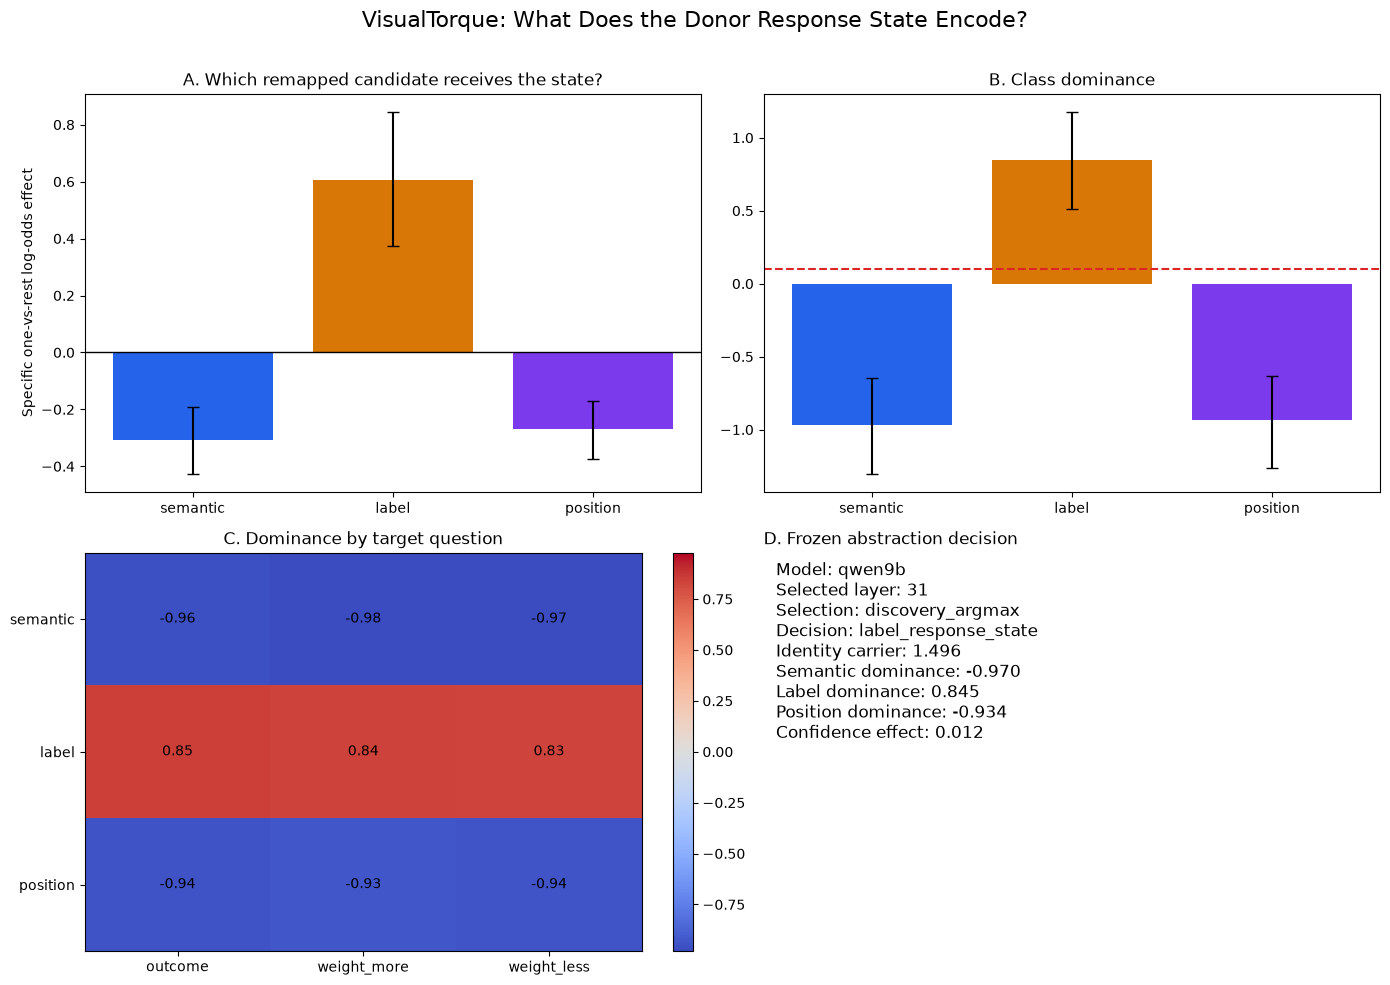

Figure: /content/drive/MyDrive/VisualTorque/results/response_state_remapping_v1/models/Qwen__Qwen3.5-9B/analysis/figures/response_state_remapping.png


In [16]:
%%cell_progress 15/17 Save the paper-facing remapping figure
cell_stage('Rendering carrier, class effects, dominance, and target consistency')
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
class_names = ('semantic', 'label', 'position')
colors = {'semantic': '#2563EB', 'label': '#D97706', 'position': '#7C3AED'}
effects = [aggregate_test(f'{name}_effect') for name in class_names]
means = np.asarray([row['mean'] for row in effects], float)
yerr = np.vstack([
    means - np.asarray([row['ci_low'] for row in effects], float),
    np.asarray([row['ci_high'] for row in effects], float) - means,
])
axes[0, 0].bar(class_names, means, color=[colors[name] for name in class_names])
axes[0, 0].errorbar(range(3), means, yerr=yerr, fmt='none', color='black', capsize=4)
axes[0, 0].axhline(0, color='black', linewidth=1)
axes[0, 0].set_title('A. Which remapped candidate receives the state?')
axes[0, 0].set_ylabel('Specific one-vs-rest log-odds effect')

dominance = [aggregate_test(f'{name}_dominance') for name in class_names]
dmeans = np.asarray([row['mean'] for row in dominance], float)
dyerr = np.vstack([
    dmeans - np.asarray([row['ci_low'] for row in dominance], float),
    np.asarray([row['ci_high'] for row in dominance], float) - dmeans,
])
axes[0, 1].bar(class_names, dmeans, color=[colors[name] for name in class_names])
axes[0, 1].errorbar(range(3), dmeans, yerr=dyerr, fmt='none', color='black', capsize=4)
axes[0, 1].axhline(DOMINANCE_SESOI, color='#DC2626', linestyle='--')
axes[0, 1].set_title('B. Class dominance')

target_matrix = np.asarray([
    [target_test(target, f'{name}_dominance')['mean'] for target in TARGET_TASKS]
    for name in class_names
])
limit = max(0.1, float(np.abs(target_matrix).max()))
image = axes[1, 0].imshow(
    target_matrix, cmap='coolwarm', vmin=-limit, vmax=limit, aspect='auto'
)
axes[1, 0].set_xticks(range(len(TARGET_TASKS)), TARGET_TASKS)
axes[1, 0].set_yticks(range(3), class_names)
axes[1, 0].set_title('C. Dominance by target question')
for i in range(3):
    for j in range(len(TARGET_TASKS)):
        axes[1, 0].text(j, i, f'{target_matrix[i, j]:.2f}', ha='center', va='center')
fig.colorbar(image, ax=axes[1, 0], fraction=0.046)

axes[1, 1].axis('off')
status = decision_frame.iloc[0]
summary = [
    f'Model: {MODEL_KEY}', f'Selected layer: {SELECTED_LAYER}',
    f"Selection: {status['selection_mode']}",
    f"Decision: {status['primary_decision']}",
    f"Identity carrier: {status['identity_carrier_effect']:.3f}",
    f"Semantic dominance: {status['semantic_dominance']:.3f}",
    f"Label dominance: {status['label_dominance']:.3f}",
    f"Position dominance: {status['position_dominance']:.3f}",
    f"Confidence effect: {status['confidence_effect']:.3f}",
]
axes[1, 1].text(0.02, 0.98, '\n'.join(summary), va='top', fontsize=12)
axes[1, 1].set_title('D. Frozen abstraction decision', loc='left')
fig.suptitle('VisualTorque: What Does the Donor Response State Encode?', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.97))
figure_path = FIGURE_DIR / 'response_state_remapping.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()
print('Figure:', figure_path)


In [17]:
%%cell_progress 16/17 Write the model-specific response-state card
cell_stage('Writing the frozen remapping decision')
interpretations = {
    'semantic_response_state': (
        'The transported state follows the donor physical side after label '
        'and position are both changed. It is an abstract side decision, not '
        'a reusable weight value.'
    ),
    'label_response_state': (
        'The transported state follows the donor output label after semantic '
        'and position remapping. Prior rescue is best viewed as output-code '
        'state transfer rather than physical-computation repair.'
    ),
    'position_response_state': (
        'The transported state follows the donor ordinal option position. '
        'Prior effects primarily modify option selection, not a physical value.'
    ),
    'generic_confidence_state': (
        'No semantic, label, or position class dominates, but the donor state '
        'reliably sharpens the response distribution. It is best described as '
        'a generic confidence state.'
    ),
    'mixed_response_state': (
        'More than one abstraction class passes the frozen gate. The final '
        'response state is mixed at this resolution.'
    ),
    'no_stable_final_token_carrier': (
        'The clean final-token carrier does not pass the confirmation gate. '
        'The earlier effect remains local to its original token scope.'
    ),
    'mixed_or_unresolved_response_state': (
        'A final-token carrier exists, but no single remapped attribute or '
        'generic-confidence account passes every frozen gate.'
    ),
}
primary_decision = str(decision_frame.iloc[0]['primary_decision'])
decision_payload = {
    'schema_version': 'response-state-remapping-decision-1.0',
    'model_key': MODEL_KEY, 'model_id': MODEL_ID,
    'resolved_revision': capture_identity['resolved_revision'],
    'prior_manifest_sha256': prior_manifest_sha256,
    'selected_layer': SELECTED_LAYER,
    'selection': selection_payload,
    'primary_decision': primary_decision,
    'decision_metrics': json.loads(decision_frame.to_json(orient='records'))[0],
    'interpretation': interpretations[primary_decision],
    'robustness_audit': robustness_payload,
    'limitations': [
        'The audit classifies a final-token carrier, not an upstream physics circuit.',
        'Qwen-9B layer selection is discovery/confirmation split and is not the prior options-token site.',
        'Qwen-27B is confirmatory at the previously frozen L63 site.',
        'The physical images are reused intentionally from the locked inverse-query support.',
    ],
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
}
write_json_atomic(ANALYSIS_DIR / 'remapping_decision.json', decision_payload)
lines = [
    '# Response-State Remapping Audit', '',
    f'- Model: `{MODEL_ID}`',
    f'- Selected layer: `{SELECTED_LAYER}`',
    f'- Decision: **{primary_decision}**', '',
    '## Interpretation', '', interpretations[primary_decision], '',
    '## Decision metrics', '',
]
for key, value in decision_payload['decision_metrics'].items():
    lines.append(f'- {key}: `{value}`')
lines.extend(['', '## Robustness', ''])
for key, value in robustness_payload.items():
    lines.append(f'- {key}: `{value}`')
lines.extend(['', '## Limits', ''])
lines.extend(f'- {value}' for value in decision_payload['limitations'])
(ANALYSIS_DIR / 'REPORT.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
display(decision_payload)
print('Report:', ANALYSIS_DIR / 'REPORT.md')


Write the model-specific response-state card:  88%|########8 | 15/17 [00:00<?, ?cell/s]

{'schema_version': 'response-state-remapping-decision-1.0',
 'model_key': 'qwen9b',
 'model_id': 'Qwen/Qwen3.5-9B',
 'resolved_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'prior_manifest_sha256': 'sha256:514419513bfe9ec3cb2aa7e3e416097917944a41eb2915797b0089d2aae2a4a9',
 'selected_layer': 31,
 'selection': {'schema_version': 'response-carrier-selection-1.0',
  'model_key': 'qwen9b',
  'selection_mode': 'discovery_argmax',
  'candidate_layers': [8, 12, 16, 20, 24, 27, 31],
  'selected_layer': 31,
  'discovery_family_ids': ['inverse_16b5c1a91ac77aab1c',
   'inverse_3b56968c4989366197',
   'inverse_4048af2c80daa1947c',
   'inverse_439e870a27a5205e36',
   'inverse_47f4cd70e5801e5210',
   'inverse_4a94dd1c49635d6345',
   'inverse_55eee932b564802c16',
   'inverse_73972ca82f8c97b83a',
   'inverse_7445bc8913d0977a89',
   'inverse_99a6e0673dd1e57a29',
   'inverse_9d3a95e07f227c906c',
   'inverse_9d93d64dde8a694ab9',
   'inverse_c3a0fa3a06e9a0f18f',
   'inverse_c98c8a8516acc71d6a',
 

Report: /content/drive/MyDrive/VisualTorque/results/response_state_remapping_v1/models/Qwen__Qwen3.5-9B/analysis/REPORT.md


In [18]:
%%cell_progress 17/17 Run the locked-support cross-model synthesis
cell_stage('Comparing abstraction classes when both model runs exist')
paths = {
    key: SHARED_ROOT / 'models' / spec['model_slug']
    / 'analysis' / 'remapping_decision.json'
    for key, spec in MODEL_SPECS.items()
}
available = {
    key: json.loads(path.read_text(encoding='utf-8'))
    for key, path in paths.items() if path.is_file()
}
print('Available:', sorted(available))
missing = [key for key in PRIMARY_MODEL_KEYS if key not in available]
if missing:
    print('Cross-model synthesis deferred. Still run:', missing)
else:
    hashes = {available[key]['prior_manifest_sha256'] for key in PRIMARY_MODEL_KEYS}
    assert len(hashes) == 1
    rows = []
    for key in PRIMARY_MODEL_KEYS:
        payload = available[key]
        metrics = payload['decision_metrics']
        rows.append({
            'model_key': key,
            'selected_layer': payload['selected_layer'],
            'selection_mode': metrics['selection_mode'],
            'confirmatory_model': bool(MODEL_SPECS[key]['confirmatory_model']),
            'primary_decision': payload['primary_decision'],
            'identity_carrier_effect': metrics['identity_carrier_effect'],
            'semantic_dominance': metrics['semantic_dominance'],
            'label_dominance': metrics['label_dominance'],
            'position_dominance': metrics['position_dominance'],
        })
    frame = pd.DataFrame(rows)
    same_class = frame['primary_decision'].nunique() == 1
    interpretation = (
        'Both Qwen scales select the same response abstraction, but only '
        'Qwen-27B used a fully prior-frozen site.' if same_class else
        'The two Qwen scales select different response abstractions; describe '
        'this as model-specific organization, not a monotonic scaling law.'
    )
    frame.to_csv(CROSS_MODEL_DIR / 'cross_model_remapping_summary.csv', index=False)
    write_json_atomic(CROSS_MODEL_DIR / 'cross_model_decision.json', {
        'schema_version': 'response-state-remapping-cross-model-1.0',
        'prior_manifest_sha256': next(iter(hashes)),
        'same_response_class': bool(same_class),
        'model_decisions': {
            key: available[key]['primary_decision'] for key in PRIMARY_MODEL_KEYS
        },
        'interpretation': interpretation,
    })
    display(frame)
    print(interpretation)
    print('Cross-model outputs:', CROSS_MODEL_DIR)


Run the locked-support cross-model synthesis:  94%|#########4| 16/17 [00:00<?, ?cell/s]

Available: ['qwen9b']
Cross-model synthesis deferred. Still run: ['qwen27b']
